# Public proteomics imputation benchmark
### TCGA-UCEC: reconstruction and hypertension association preservation

## Goal
Run the paper's **nine imputation implementations** on public tumor RPPA data: KNN, Iterative, MissForest, SoftImpute, AE, DAE, VAE, GAIN, and Transformer. Tune using additional observed-cell holdouts, freeze one configuration per method, compare reconstruction, then measure preservation of protein associations.

**Scientific scope:** hypertension is a cardiovascular risk factor. These are tumor protein measurements from patients with endometrial cancer. This notebook demonstrates the pipeline and does not reproduce the MyoVasc CVD/plaque results or establish cardiovascular biomarkers. Hypertension is a **consistent recorded status across baseline and follow-up**, not a verified baseline diagnosis or incident endpoint.

**Execution modes:** `demo` uses 160 patients, 60 antibody/protein features, two tuning trials per method, 30 epochs, and final seed 42. `paper_budget` uses the complete common panel, all eligible patients, the paper's method-specific trial counts, and five final seeds. Neither mode reproduces the paper's private cohort.

Use **Runtime → Run all** in a fresh Python runtime. CPU works; a GPU can speed up neural models. The first setup cell clones the source from GitHub. No Google Drive mount, ZIP upload, or saved R-library archive is required.

## Setup
### 1. Clone the source repository
Run this cell in Colab. It clones the public GitHub repository into `/content/imputation-reproducibility`, sets the working directory, and records the checked-out commit. No ZIP download or upload is needed.

Rerunning the cell reuses the existing checkout so it does not overwrite files or silently change code during an experiment. To test a later repository version, start a fresh Colab session and reopen this notebook. Local readers can open the notebook from their existing checkout.

In [2]:
from pathlib import Path
import os, sys, shutil, subprocess

REPOSITORY_URL = 'https://github.com/niloofarmaani/proteomics-imputation-benchmark-cvd-association.git'
REPOSITORY_REF = 'main'
CLONE_DIR = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / 'imputation-reproducibility'

# Reuse an existing checkout. In Colab, prefer the dedicated clone directory.
ROOT = next((p.resolve() for p in [CLONE_DIR, Path.cwd(), *Path.cwd().parents]
             if (p/'.git').exists() and (p/'reproducibility/pipeline.py').is_file()), None)
# Local readers can also run directly from an already extracted project folder.
if ROOT is None and not Path('/content').is_dir():
    ROOT = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                 if (p/'reproducibility/pipeline.py').is_file()), None)

if ROOT is None:
    if shutil.which('git') is None:
        raise RuntimeError('Git is not installed. Install Git before running this cell.')
    if CLONE_DIR.exists():
        raise RuntimeError(f'{CLONE_DIR} already exists but is not a valid project checkout. Choose a different CLONE_DIR.')
    print('Cloning the source repository...')
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', REPOSITORY_REF,
                    REPOSITORY_URL, str(CLONE_DIR)],
                   env={**os.environ, 'GIT_TERMINAL_PROMPT': '0'}, check=True)
    ROOT = CLONE_DIR.resolve()

if not (ROOT/'reproducibility/pipeline.py').is_file():
    raise RuntimeError('The checkout does not contain the benchmark source modules.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Repository:', ROOT)
if (ROOT/'.git').exists():
    SOURCE_COMMIT = subprocess.check_output(['git', '-C', str(ROOT), 'rev-parse', 'HEAD'], text=True).strip()
    print('Source commit:', SOURCE_COMMIT)

Repository: /content/imputation-reproducibility
Source commit: f9e440444b0ea59803ccf81cc926c62e2b06af33


### 2. Install Python and R dependencies
This uses only the R packages actually needed by the nine methods: `Metrics`, `impute`, and `missRanger` plus their dependencies. The older notebook installed additional packages used by other analyses. Compiled R libraries from Drive can be incompatible with a new runtime; installing from source avoids relying on that archive.

The Python environment is pinned for the reference run. Colab keeps its provided PyTorch build. If the installer requests a kernel restart, restart once, then rerun from the beginning.

In [3]:
import subprocess
import importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and os.environ.get('IMPUTATION_SKIP_INSTALL') != '1':
    loaded_before = {name: getattr(sys.modules.get(name), '__version__', None) for name in ['numpy', 'pandas', 'scipy', 'sklearn']}
    subprocess.run(['bash', str(ROOT/'scripts/install_colab.sh')], check=True)
    package_names = {'sklearn': 'scikit-learn'}
    changed = [name for name, version in loaded_before.items() if version is not None and version != importlib.metadata.version(package_names.get(name, name))]
    if changed:
        raise RuntimeError('Installed versions changed for already loaded packages: ' + ', '.join(changed) + '. Restart the runtime, then Run all again. Uploaded source files remain available.')
else:
    print('Local run: install requirements.txt and run Rscript scripts/install_r.R before continuing.')

### 3. Select the experiment budget
The reduced demo is for verifying execution. Its rankings depend on the small panel, short training, and limited search. A single seed does not estimate simulation uncertainty. Do not choose settings after looking at association preservation.

In [4]:
import json
import numpy as np
import pandas as pd
from IPython.display import display
from reproducibility.data import download_sources, build_tcga_cohort
from reproducibility.methods import METHODS, PAPER_TRIALS, preflight
from reproducibility.pipeline import Settings, initialize_run, tune, evaluate, association_analysis
from reproducibility.plots import reconstruction_plot, preservation_plot, volcano

MODE = 'demo'  # 'demo' or 'paper_budget'
settings = Settings() if MODE == 'demo' else Settings.paper_budget()
MAX_SAMPLES, MAX_PROTEINS = (160, 60) if MODE == 'demo' else (None, None)
OUTCOME = 'hypertension'
COVARIATES = ['age', 'diabetes', 'bmi']
# A new directory protects against accidentally mixing independent experiments.
OUT = ROOT/'results'/pd.Timestamp.now(tz='UTC').strftime('tcga_%Y%m%dT%H%M%S%fZ')
CACHE = ROOT/'data/raw'
print(preflight(list(settings.methods)))
display(pd.DataFrame({'Method': METHODS, 'Demo trials': settings.trials, 'Paper-budget trials': [PAPER_TRIALS[m] for m in METHODS]}))

{'torch': '2.11.0+cpu', 'device': 'cpu', 'methods': ['KNN', 'Iterative', 'MissForest', 'SoftImpute', 'AE', 'DAE', 'VAE', 'GAIN', 'Transformer']}


,Method,Demo trials,Paper-budget trials
0,KNN,2,20
1,Iterative,2,12
2,MissForest,2,20
3,SoftImpute,2,15
4,AE,2,20
5,DAE,2,20
6,VAE,2,20
7,GAIN,2,15
8,Transformer,2,6


## Steps
### 4. Download and verify the public inputs
Sources: [cBioPortal Datahub](https://github.com/cBioPortal/datahub/tree/master/public/ucec_tcga) RPPA; GDC TCGA-UCEC clinical patient and follow-up Biotab files. `configs/data_sources.json` records fixed file UUIDs/URLs and SHA-256 hashes. A changed download stops execution instead of silently changing the dataset.

The source RPPA matrix has antibody identifiers, including phosphorylation-specific features. Preserve these complete identifiers; merging on gene symbols would combine distinct assays. The published study provides [background on TCGA-UCEC proteomics](https://gdc.cancer.gov/about-data/publications/ucec_2013).

In [5]:
paths = download_sources(CACHE)
x, metadata, cohort_audit = build_tcga_cohort(paths, max_samples=MAX_SAMPLES, max_proteins=MAX_PROTEINS)
display(pd.Series({k: v for k, v in cohort_audit.items() if not isinstance(v, (dict, list))}, name='Cohort audit'))
display(metadata[OUTCOME].value_counts().rename(index={0: 'Recorded no hypertension', 1: 'Recorded hypertension'}).to_frame('Patients'))
display(metadata.drop(columns=OUTCOME).isna().sum().to_frame('Missing covariate values'))
print('Conflicting clinical records:', cohort_audit['discordant_patient_records_excluded_per_phenotype'])
print('Native incomplete assay features removed:', len(cohort_audit['native_incomplete_features_removed']))

,Cohort audit
study,TCGA-UCEC / cBioPortal ucec_tcga Firehose Legacy
assay,tumor reverse-phase protein array (RPPA); anti...
endpoint,GDC recorded hypertension across baseline and ...
primary_tumor_samples,440
duplicate_patient_samples_removed,0
selected_proteins,60
patients_before_complete_case_selection,440
protein_complete_cases,440
missing_hypertension,60
eligible_complete_cases,380


,Patients
hypertension,
Recorded hypertension,97
Recorded no hypertension,63


,Missing covariate values
age,1
diabetes,10
bmi,8


Conflicting clinical records: {'hypertension_diagnosis': 5, 'diabetes_diagnosis_indicator': 2}
Native incomplete assay features removed: 13


### 5. Define the reference cohort and association model
The full public-data cohort contains **380 patients with a consistent observed hypertension status and 195 RPPA features in the common complete panel**, using the source hashes supplied with this release. The demo selects 160 patients at seed 42 and the first 60 alphabetically ordered features, independently of association strength. Thirteen batch-specific incomplete features are excluded to obtain observed reference measurements; native missing values are never treated as known truth.

One primary tumor sample per patient is selected deterministically. Yes/no clinical records map to 1/0. Unrecorded statuses and patients with conflicting yes/no hypertension records are excluded. Follow-up timing is not harmonized, so this is an exploratory recorded-status association.

For each protein: `logit(P(hypertension=1)) = intercept + beta × standardized_protein + age + diabetes + BMI`. Age/BMI use median replacement, diabetes uses the mode. A fixed covariate design and identical patients are used in every scan. Sex is constant in this cohort and omitted. Hypertension is the outcome, so it cannot also be an adjustment covariate. These adjustments differ from the paper because the public cohort and endpoint differ.

The reference is complete for the retained panel, not the unselected source population. This selection can affect generalizability. Associations are preservation targets, not causal effects.

In [6]:
from reproducibility.associations import covariate_design
assert x.index.equals(metadata.index) and not x.index.has_duplicates
assert np.isfinite(x.to_numpy()).all()
assert set(metadata[OUTCOME].unique()) == {0, 1}
metadata['diabetes'] = metadata['diabetes'].map({0: 'no', 1: 'yes'})
OUT = initialize_run(OUT, x, metadata, settings, OUTCOME, COVARIATES)
(OUT/'cohort_audit.json').write_text(json.dumps(cohort_audit, indent=2, default=int))
(OUT/'data_sources.json').write_text((ROOT/'configs/data_sources.json').read_text())
display(covariate_design(metadata, COVARIATES).head())
print('Run directory:', OUT)

,const,age,bmi,diabetes_yes
eid,,,,
TCGA-5S-A9Q8-01,1.0,51.0,32.769395,1.0
TCGA-A5-A0G3-01,1.0,61.0,23.507805,0.0
TCGA-A5-A0G9-01,1.0,79.0,27.717685,0.0
TCGA-A5-A0GA-01,1.0,67.0,31.141869,0.0
TCGA-A5-A0GB-01,1.0,65.0,44.811754,0.0


Run directory: /content/imputation-reproducibility/results/tcga_20261016T092942025873Z


### 6. Inspect the missingness and validation masks
All methods receive the same masks. MCAR removes uniformly sampled cells. MAR uses a random rank block sorted by another protein. MNAR uses a random rank block sorted by the target protein. Each column loses `floor(n × fraction)` cells. These reproduce the **rank-block idea** in Jenga, with deterministic candidate order and immutable protein-only sorting inputs. This is a documented adaptation rather than a bitwise reproduction of the archived preprocessing.

The MAR-labelled driver can itself be masked later; the name does not establish formal Rubin MAR conditional on the final observed matrix. MNAR here is not a below-detection-limit censoring model.

Tuning uses MAR/MNAR at 10%/30%, seed 42. Approximately 5% of each condition's remaining observed values are hidden with quantile-stratified sampling. Those extra holdouts are disjoint from simulated test omissions. Ceiling within quantile bins can make the realized validation rate exceed 5%, especially in small demos.

In [7]:
from reproducibility.missingness import corrupt, validation_mask, combo_seed
preview, simulated_mask = corrupt(x, 'MAR', .3, 42)
heldout_mask = validation_mask(preview, combo_seed(42, 'MAR', .3))
assert not (simulated_mask & heldout_mask).any()
display(pd.DataFrame({'Cells': [int(simulated_mask.sum()), int(heldout_mask.sum()), int(np.isfinite(preview.to_numpy()).sum() - heldout_mask.sum())]}, index=['Simulation omissions (final scoring)', 'Extra observed holdouts (tuning)', 'Observed cells available to fit']))

,Cells
Simulation omissions (final scoring),2880
Extra observed holdouts (tuning),600
Observed cells available to fit,6120


### 7. Tune all nine methods on validation RMSE
Optuna minimizes the equally weighted mean holdout RMSE over the four tuning conditions. One configuration per method is frozen. The objective never reads final reconstruction RMSE or association results. Neural models retain the original separate internal early-stopping holdout and final refit.

| Method | Implementation retained | Search |
|---|---|---|
| KNN | R `impute::impute.knn`, sample neighbours | neighbour count |
| Iterative | Bayesian-ridge chained regression | iterations |
| MissForest | R `missRanger` | iterations, trees, depth, sample fraction |
| SoftImpute | original iterative rank-truncated SVD | rank, iterations |
| AE | supplied PyTorch autoencoder | architecture, latent size, batch size, learning rate |
| DAE | supplied denoising autoencoder | AE settings plus corruption |
| VAE | supplied variational autoencoder | AE settings plus free bits |
| GAIN | supplied generator/discriminator imputer | network and training parameters |
| Transformer | supplied feature-token attention model | embedding dimension, learning rate |

**SoftImpute naming:** as disclosed in the paper, the supplied method does not shrink singular values and differs from standard SoftImpute. The runner retains that implementation. The original search spaces are in `legacy/Optimization/method_spaces.py`; infeasible SVD ranks are removed for small panels. Two demo trials, and even the paper's six Transformer trials, remain within Optuna's default ten-trial random startup phase.

All nine methods are required by default. A missing dependency or failed method stops the run and leaves logs and the Optuna database for diagnosis.

In [8]:
frozen = tune(x, OUT, settings)
trials = pd.read_csv(OUT/'validation_trials.csv')
display(trials[['method', 'trial', 'state', 'objective']].round(5))
display(pd.DataFrame([{'Method': method, 'Validation RMSE': item['validation_rmse'], 'Best trial': item['best_trial'], 'Frozen settings': json.dumps(item['params'])} for method, item in frozen.items()]))

Tuning KNN
Tuning Iterative
Tuning MissForest
Tuning SoftImpute
Tuning AE
Tuning DAE
Tuning VAE
Tuning GAIN
Tuning Transformer


,method,trial,state,objective
0,KNN,0,COMPLETE,0.51679
1,KNN,1,COMPLETE,0.48182
2,Iterative,0,COMPLETE,0.44314
3,Iterative,1,COMPLETE,0.44315
4,MissForest,0,COMPLETE,0.45177
5,MissForest,1,COMPLETE,0.44512
6,SoftImpute,0,COMPLETE,0.60822
7,SoftImpute,1,COMPLETE,0.58965
8,AE,0,COMPLETE,0.51439
9,AE,1,COMPLETE,0.54290


,Method,Validation RMSE,Best trial,Frozen settings
0,KNN,0.481819,1,"{""k"": 15}"
1,Iterative,0.443136,0,"{""max_iter"": 25, ""tol"": 0.001, ""n_nearest_feat..."
2,MissForest,0.445118,1,"{""niter"": 3, ""ntree"": 200, ""max_depth"": 20, ""s..."
3,SoftImpute,0.589655,1,"{""rank_max"": 5, ""maxit"": 50}"
4,AE,0.514389,0,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
5,DAE,0.530448,0,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
6,VAE,0.553170,0,"{""batch_size"": 64, ""learning_rate"": 0.00076611..."
7,GAIN,0.487109,0,"{""batch_size"": 64, ""lr"": 0.0007661100707771367..."
8,Transformer,0.559179,1,"{""batch_size"": 32, ""nhead"": 4, ""num_layers"": 1..."


### 8. Compare final reconstruction with frozen parameters
Final fits use the original simulated omissions with **no extra tuning holdouts**. RMSE is calculated only at simulated missing entries. Neither sample IDs nor clinical variables enter the imputers. The runner passes a dummy metadata label and an observed-value surrogate to legacy APIs so hidden reference values cannot enter fitting. Legacy diagnostic RMSE in logs is not the benchmark score; use `reconstruction.csv`.

Final KNN: MCAR_0.1_seed42
Final Iterative: MCAR_0.1_seed42
Final MissForest: MCAR_0.1_seed42
Final SoftImpute: MCAR_0.1_seed42
Final AE: MCAR_0.1_seed42
Final DAE: MCAR_0.1_seed42
Final VAE: MCAR_0.1_seed42
Final GAIN: MCAR_0.1_seed42
Final Transformer: MCAR_0.1_seed42
Final KNN: MCAR_0.3_seed42
Final Iterative: MCAR_0.3_seed42
Final MissForest: MCAR_0.3_seed42
Final SoftImpute: MCAR_0.3_seed42
Final AE: MCAR_0.3_seed42
Final DAE: MCAR_0.3_seed42
Final VAE: MCAR_0.3_seed42
Final GAIN: MCAR_0.3_seed42
Final Transformer: MCAR_0.3_seed42
Final KNN: MCAR_0.5_seed42
Final Iterative: MCAR_0.5_seed42
Final MissForest: MCAR_0.5_seed42
Final SoftImpute: MCAR_0.5_seed42
Final AE: MCAR_0.5_seed42
Final DAE: MCAR_0.5_seed42
Final VAE: MCAR_0.5_seed42
Final GAIN: MCAR_0.5_seed42
Final Transformer: MCAR_0.5_seed42
Final KNN: MAR_0.1_seed42
Final Iterative: MAR_0.1_seed42
Final MissForest: MAR_0.1_seed42
Final SoftImpute: MAR_0.1_seed42
Final AE: MAR_0.1_seed42
Final DAE: MAR_0.1_seed42
Final VAE: M

mechanism       MAR                    MCAR                    MNAR          \
fraction        0.1     0.3     0.5     0.1     0.3     0.5     0.1     0.3   
method                                                                        
AE           0.4799  0.4997  0.5355  0.4977  0.5261  0.5464  0.3897  0.4344   
DAE          0.4895  0.5323  0.5266  0.5115  0.5301  0.5350  0.3846  0.4261   
GAIN         0.4634  0.4793  0.4894  0.4916  0.4974  0.5193  0.3471  0.3620   
Iterative    0.3913  0.4863  0.4947  0.4101  0.4840  0.4975  0.3415  0.4545   
KNN          0.4667  0.4917  0.5280  0.4894  0.4900  0.5215  0.3549  0.3912   
MissForest   0.4298  0.4469  0.4642  0.4500  0.4491  0.4785  0.3298  0.3666   
SoftImpute   0.5028  0.5467  0.5919  0.4951  0.5732  0.6513  0.4148  0.5035   
Transformer  0.5299  0.5339  0.5397  0.5719  0.5521  0.5470  0.3734  0.4142   
VAE          0.5262  0.5319  0.5424  0.5628  0.5432  0.5492  0.3990  0.4369   

mechanism            
fraction        0.5  
method               
AE           0.5509  
DAE          0.5515  
GAIN         0.4526  
Iterative    0.5104  
KNN          0.5425  
MissForest   0.4945  
SoftImpute   0.6066  
Transformer  0.5022  
VAE          0.5838

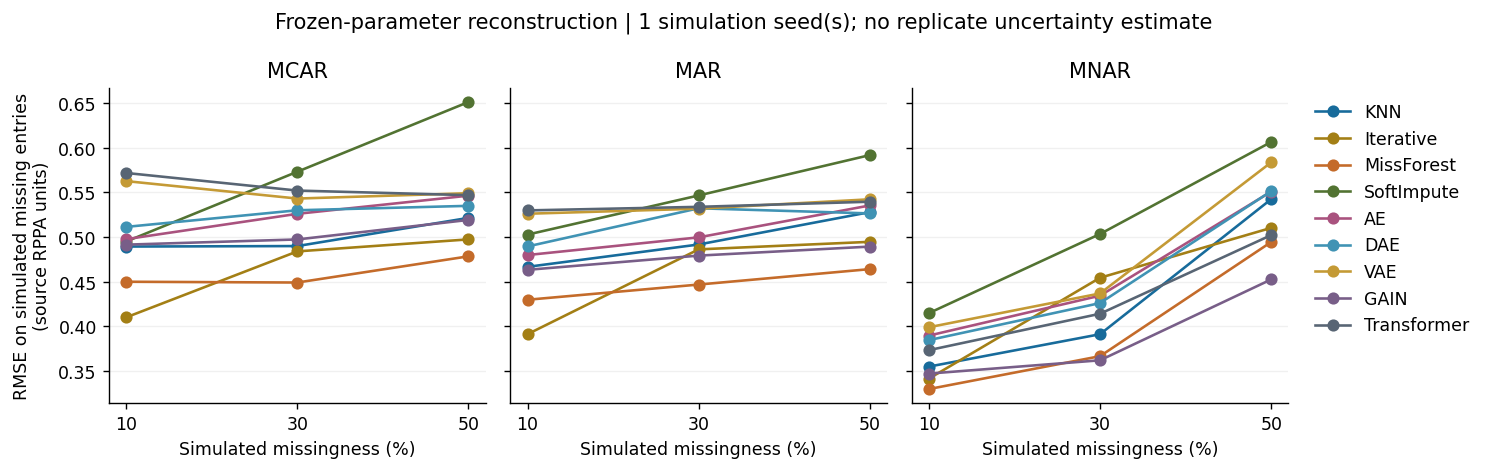

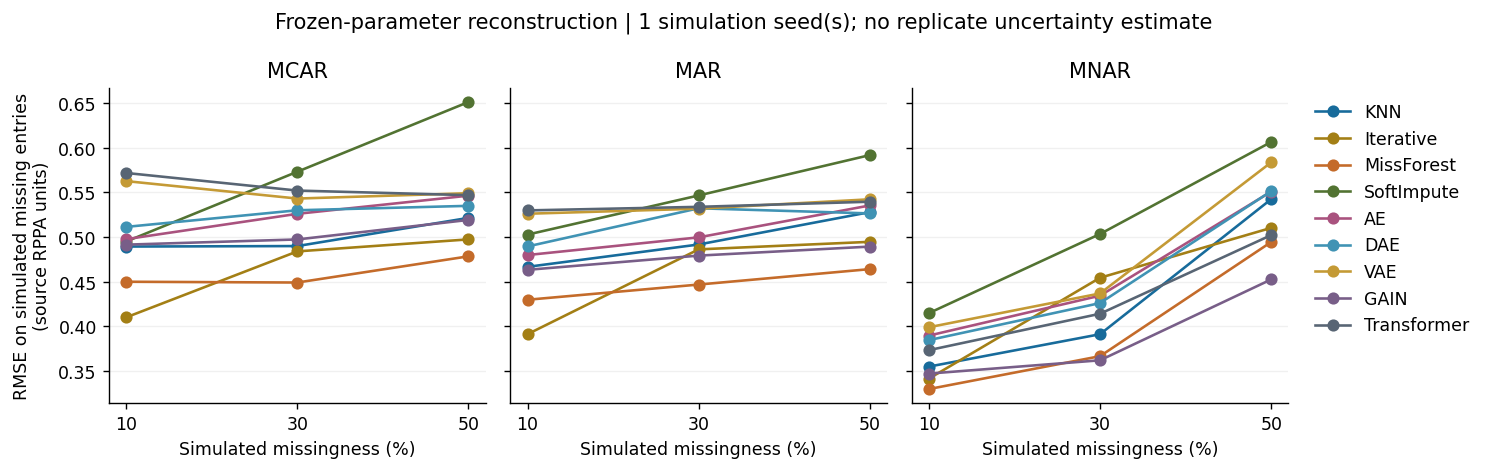

In [9]:
reconstruction = evaluate(x, OUT, settings, frozen)
summary = reconstruction.groupby(['method', 'mechanism', 'fraction']).rmse.mean().unstack(['mechanism', 'fraction'])
display(summary.round(4))
reconstruction_plot(reconstruction, OUT)

### 9. Fit the reference and imputed association scans
Each protein is standardized within its own reference or imputed dataset. Binomial GLMs produce beta, standard error, Wald z, and p-value; Benjamini-Hochberg correction is performed separately within each scan. Failed/nonconverged/separated models are retained with a status and missing inference.

Association preservation uses **final seed 42**, matching the paper's single-seed downstream protocol. Its averages over conditions are not averages over independent simulation replicates.

Metrics: signed z-Spearman, beta-Spearman, top-20/top-50 overlap, coefficient-sign concordance, FDR-set Jaccard, reference-FDR retention, and beta RMSE. Empty FDR sets yield undefined Jaccard/retention where the denominator is zero. They are shown as `NA`, not perfect agreement.

,n,beta,se,z,p,status,q
protein,,,,,,,
CHEK2|Chk2,160,-0.71821,0.20927,-3.43197,0.00060,ok,0.03595
EGFR|EGFR_pY1173,160,0.46050,0.18825,2.44618,0.01444,ok,0.43314
CASP8|Caspase-8,160,-0.34193,0.20759,-1.64715,0.09953,ok,0.51521
CCNB1|Cyclin_B1,160,-0.30166,0.18504,-1.63028,0.10304,ok,0.51521
BAX|Bax,160,0.34400,0.19170,1.79449,0.07274,ok,0.51521
CDKN1B|p27_pT157,160,0.31752,0.18702,1.69777,0.08955,ok,0.51521
BID|Bid,160,0.30523,0.18537,1.64665,0.09963,ok,0.51521
CCND1|Cyclin_D1,160,0.34428,0.20331,1.69338,0.09038,ok,0.51521
CDH2|N-Cadherin,160,0.37833,0.18599,2.03420,0.04193,ok,0.51521


Reference model status counts: {'ok': 60}


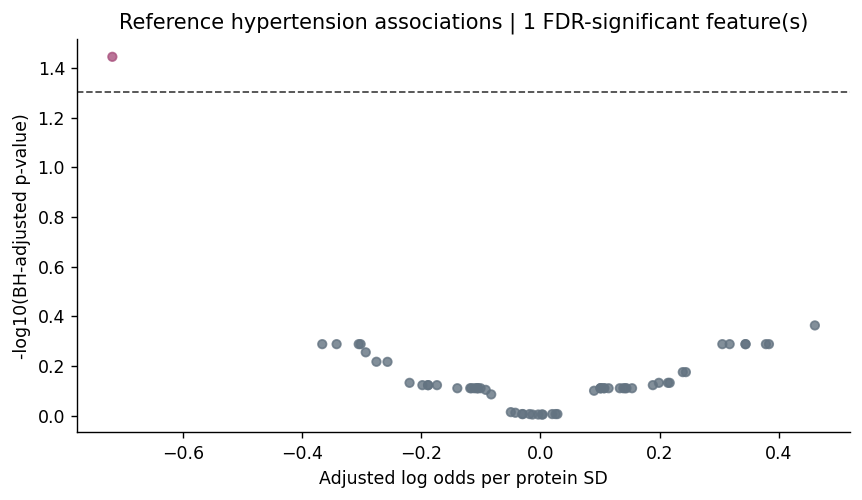

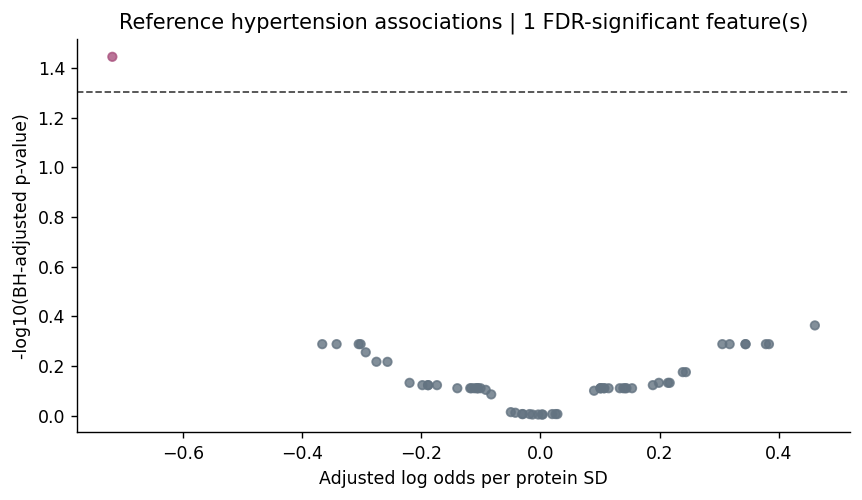

In [10]:
reference_associations, association_metrics = association_analysis(x, metadata, OUTCOME, COVARIATES, OUT, settings, reconstruction)
display(reference_associations.sort_values('q').head(10).round(5))
print('Reference model status counts:', reference_associations.status.value_counts().to_dict())
volcano(reference_associations, OUT)

### 10. Compare association preservation across conditions
Higher correlation/overlap/retention is better. Lower coefficient RMSE is better. Poor reconstruction and poor association preservation need not rank methods identically. Interpret the FDR metrics alongside the number of reference discoveries and failed fits.

In the 60-feature demo, two independent random top-50 sets have expected overlap **50/60 = 83.3%**. Interpret top-50 overlap against that baseline. Signed z-Spearman and top-20 overlap are more informative in this small panel; use the 195-feature mode for a larger top-50 comparison universe.

,method,mechanism,fraction,z_spearman,top20_overlap,top50_overlap,fdr_jaccard,fdr_retention,n_ref_fdr,n_imp_fdr,n_failed_imp
0,KNN,MCAR,0.1,0.964,0.85,0.88,1.0,1.0,1,1,0
1,Iterative,MCAR,0.1,0.982,0.90,0.92,1.0,1.0,1,1,0
2,MissForest,MCAR,0.1,0.967,0.90,0.90,1.0,1.0,1,1,0
3,SoftImpute,MCAR,0.1,0.976,0.90,0.92,1.0,1.0,1,1,0
4,AE,MCAR,0.1,0.971,0.90,0.92,1.0,1.0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
76,AE,MNAR,0.5,0.773,0.70,0.84,0.0,0.0,1,0,0
77,DAE,MNAR,0.5,0.842,0.55,0.90,0.0,0.0,1,0,0
78,VAE,MNAR,0.5,0.825,0.70,0.86,0.0,0.0,1,0,0
79,GAIN,MNAR,0.5,0.893,0.75,0.90,0.0,0.0,1,1,0


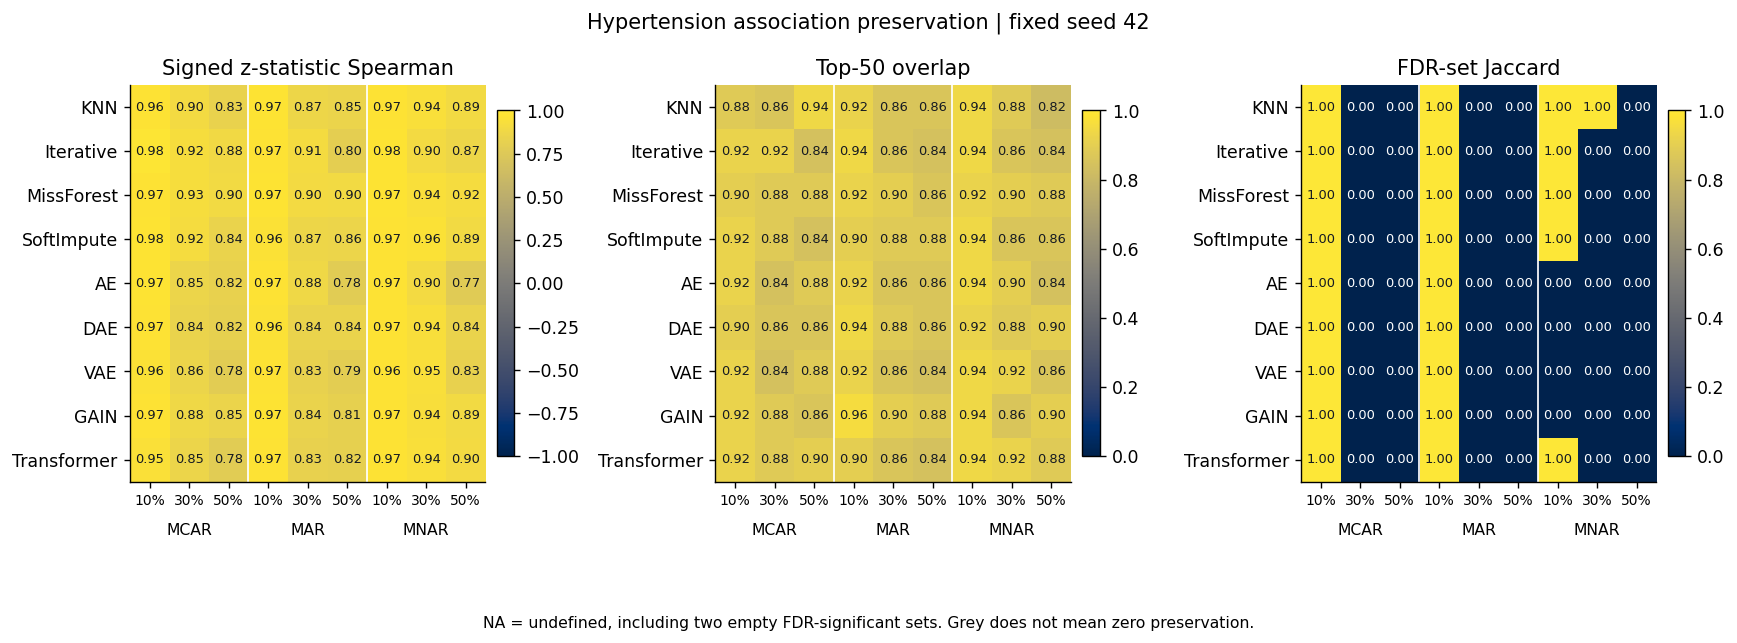

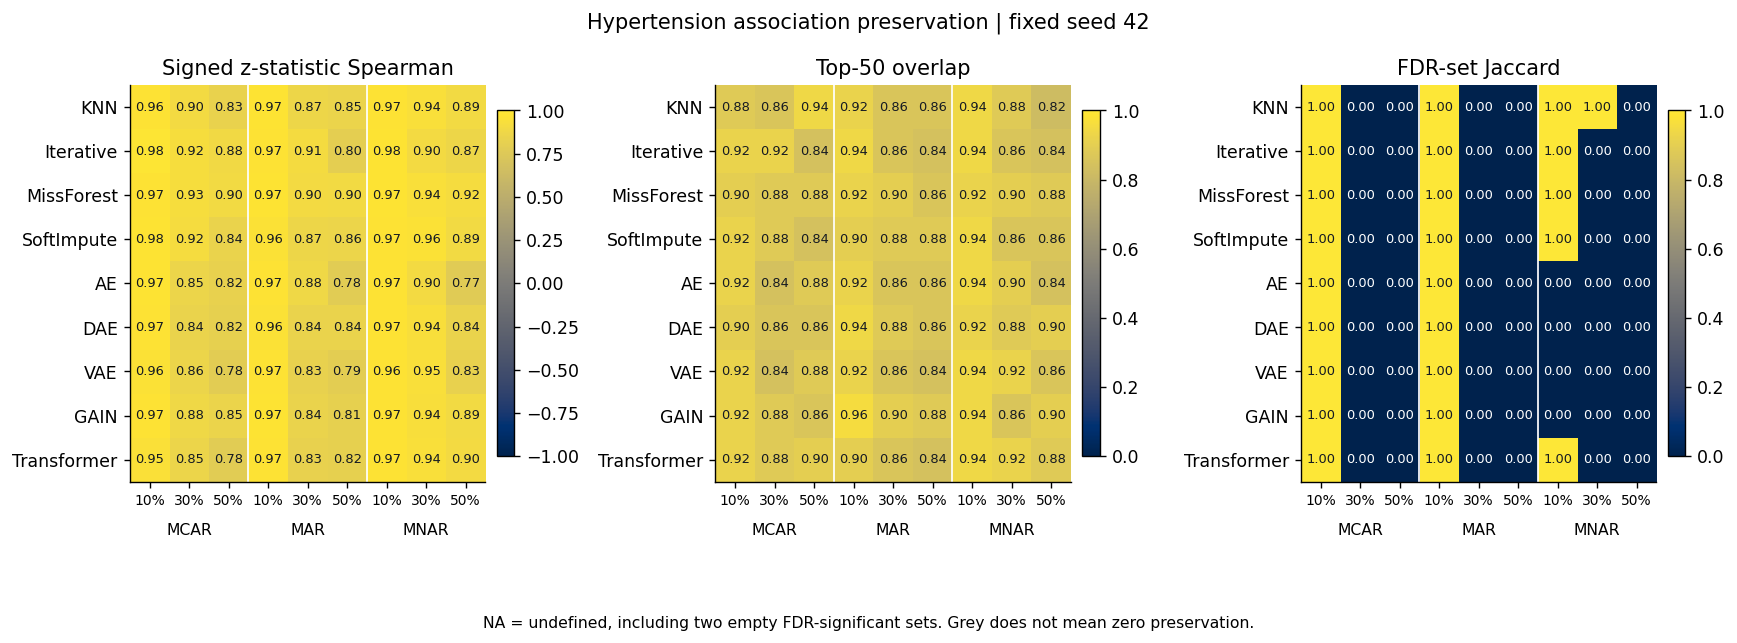

In [11]:
display(association_metrics[['method', 'mechanism', 'fraction', 'z_spearman', 'top20_overlap', 'top50_overlap', 'fdr_jaccard', 'fdr_retention', 'n_ref_fdr', 'n_imp_fdr', 'n_failed_imp']].round(3))
preservation_plot(association_metrics, OUT)

## Checks
### 11. Verify experiment coverage and export provenance
The run stores exact masks, validation trials, frozen parameters, completed matrices, association scans, source hashes, environment versions, timing, and method logs. No conclusions are generated from unexecuted code.

In [12]:
expected = len(settings.methods)*len(settings.mechanisms)*len(settings.fractions)*len(settings.final_seeds)
assert len(reconstruction) == expected
assert len(association_metrics) == len(settings.methods)*len(settings.mechanisms)*len(settings.fractions)
assert np.isfinite(reconstruction.rmse).all()
assert set(reconstruction.method) == set(settings.methods)
print(f'Complete reconstruction grid: {len(reconstruction)}/{expected}')
print('Mean preservation over conditions at fixed association seed:')
display(association_metrics.groupby('method')[['z_spearman','top50_overlap','fdr_jaccard','beta_rmse']].mean().round(4))
print('Reference FDR-significant features:', int((reference_associations.q < .05).sum()))
print('Undefined FDR Jaccard rows:', int(association_metrics.fdr_jaccard.isna().sum()))
subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'], cwd=ROOT, check=True)

Complete reconstruction grid: 81/81
Mean preservation over conditions at fixed association seed:


,z_spearman,top50_overlap,fdr_jaccard,beta_rmse
method,,,,
AE,0.8788,0.8844,0.2222,0.1011
DAE,0.8890,0.8889,0.2222,0.0938
GAIN,0.9027,0.9000,0.2222,0.0888
Iterative,0.9120,0.8844,0.3333,0.0875
KNN,0.9097,0.8844,0.4444,0.0870
MissForest,0.9322,0.8933,0.3333,0.0796
SoftImpute,0.9152,0.8844,0.3333,0.0861
Transformer,0.8899,0.8933,0.3333,0.0934
VAE,0.8795,0.8867,0.2222,0.0969


Reference FDR-significant features: 1
Undefined FDR Jaccard rows: 0


CompletedProcess(args=['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

## Next Steps
### 12. Save the run and move to your GitHub repository
Download this archive before the Colab runtime ends. It contains public-data example outputs, not MyoVasc data. To rerun after tuning, keep the complete run directory and load its frozen-parameter JSON with the same inputs and settings. Starting a new notebook run creates a separate directory.

The source repository and Colab link are configured. For publication, execute this notebook in a clean Colab runtime and tag the tested commit. The included `docs/REPRODUCIBILITY.md` distinguishes the public demonstration from exact paper reproduction. Use the local/private data loader to connect authorized MyoVasc protein and phenotype tables; the original scripts remain under `legacy/`. Do not upload restricted participant data or private outputs.

In [13]:
import shutil
archive = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('Output archive:', archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Output archive: /content/imputation-reproducibility/results/tcga_20261016T092942025873Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>